# Project Part 3 Notebook and Modules

Using
Open: 
M67, NGC 2243, NGC 2420
Globular: M4, 47 Tuc, Omega Centauri

In [46]:
#from characterize_CCD lab
import os #Functions to interact with the computer system like files
from astropy.io import fits #Allows handling of fits files input/output
from astropy.wcs import WCS #Allows world coordinate system functions
from astropy.nddata import CCDData #Allows storage of an image including its units
import astropy.units as u #Easy shortcut for attaching units to numbers
import numpy as np #Numpy, various array and statistics functions for handling data
from matplotlib import pyplot as plt #Allows plotting the images and displaying
from scipy.stats import scoreatpercentile #How the pixel values are cut to display an image useful to human eyes
import glob #Pattern-matching syntax, we used it in reduction lab for picking out the right fits to combine by their file names.
%matplotlib inline
#The above is a jupyter notebook thing which makes the plots appear right below the cells that call to display
from ccdproc import ImageFileCollection, Combiner, combine #Tools for stacking raw frames might not be needed since our data is already processed
from ccdproc import wcs_project #Reprojects images using WCS onto new coordinate grids when combining dithered images

#from cluster photometry lab
from photutils.detection import DAOStarFinder #Finds stars in an image
from astropy.stats import sigma_clipped_stats #Allows clipping out of stuff by their sigma value and gives stats on data
from photutils.aperture import CircularAperture #Place circular apertures on stars
from astropy.visualization import SqrtStretch #Square-root stretch so faint and bright stars both show, adapt image for human viewing
from astropy.visualization.mpl_normalize import ImageNormalize #Applies a stretch when displaying an image
from astropy.coordinates import SkyCoord #Stores positions in sky and matches the positions to stars in catalogs
from photutils.psf import fit_fwhm #Used to fit a gaussian onto stars and measure fwhm


The imports we anticipate using are above, comments give an explanation for each. We will read the images and headers with astropy (fits, WCS, units). To display the images we use matplotlib and scoreatpercentile from scipy, matplotlib also shows the CMDs. To measure stars we will use photutils, fit_fwhm to measure fwhm, DAOStarFinder to detect stars. sigma_clipped_stats will be used to find noise so we can get rid of it, and CircularAperture to place apertures on the stars. Star positions will be converted to RA and Dec with WCS and matched with SkyCoord. Numpy handles data in arrays and will probably be used for some other statistics handling. glob and os help with files and system interaction. Other things like ccdproc and astropy CCDData are for combining images which we might use to increase the size of the pictures and get the whole cluster.

Some software that aren't python modules/packages I plan to use are DS9, VSCode, Github, legacysurvey viewer, WSL.

In [47]:
def imdisplay(image, v1perc=10, v2perc=95):
    '''
    display an image 
    OPTIONAL KEYWORD PARAMETERS
    v1perc: one end of the colormap assigned to the v1perc percent lowest flux 
    v2perc: the other end of the colormap assigned to the v2perc percent highest flux    
    '''
    # make sure image is an np array
    nimage = np.array(image)
    # determine the pixel values at the 10th and 95th percentile
    v1 = scoreatpercentile(nimage,v1perc)
    v2 = scoreatpercentile(nimage,v2perc)
    # display using imshow
    #
    # you can play with alternate cmaps in the function below, such as "viridis" or "gray"
    # The 'gray_r' color map reverses the color-scale so that dark display pixels are the brightest in the image
    #
    # vmin and vmax set the min and max pixel values that
    # will be mapped to the extremes of the colormap
    plt.imshow(nimage,cmap='gray_r',vmin=v1,vmax=v2)
    plt.colorbar(fraction=.08)

In [57]:
plt.figure()
data, header = fits.getdata('NGC2420_Brick.fits',header=True)
#Legacy Surveys DR11-south data for brick 1146p215 is where it was taken from
#Brick bounds: RA [114.5455 to 114.8137], Dec [21.3750 to 21.6250]
#https://www.legacysurvey.org/viewer/data-for-radec/?ra=114.5979&dec=21.5733&layer=ls-dr11&ralo=114.3797&rahi=114.8169&declo=21.4627&dechi=21.6708

print(data.shape) #Couldn't get why the lab code didn't work used this to get dimensions of the data, found it stored 3 bands.

#Unlike the fits files from labs the brick from legacysurvey.org has all the bands in one file, need to separate by data array to ge the different bands
data_g = data[0].astype(float)
data_r = data[1].astype(float)
data_z = data[2].astype(float)

for key in header:
        print(key, '=', header[key])

(3, 256, 256)
SIMPLE = True
BITPIX = -32
NAXIS = 3
NAXIS1 = 256
NAXIS2 = 256
NAXIS3 = 3
EXTEND = True
COMMENT =   FITS (Flexible Image Transport System) format is defined in 'Astronomy
  and Astrophysics', volume 376, page 359; bibcode: 2001A&A...376..359H
COMMENT =   FITS (Flexible Image Transport System) format is defined in 'Astronomy
  and Astrophysics', volume 376, page 359; bibcode: 2001A&A...376..359H
SURVEY = LegacySurvey
VERSION = DR11
IMAGETYP = IMAGE
BANDS = grz
BAND0 = g
BAND1 = r
BAND2 = z
CTYPE1 = RA---TAN
CTYPE2 = DEC--TAN
CRVAL1 = 114.5979
CRVAL2 = 21.5733
CRPIX1 = 128.5
CRPIX2 = 128.5
CD1_1 = -0.000138888888888889
CD1_2 = 0.0
CD2_1 = 0.0
CD2_2 = 0.000138888888888889
IMAGEW = 256
IMAGEH = 256


<Figure size 640x480 with 0 Axes>

Text(0.5, 1.0, 'g-band fits')

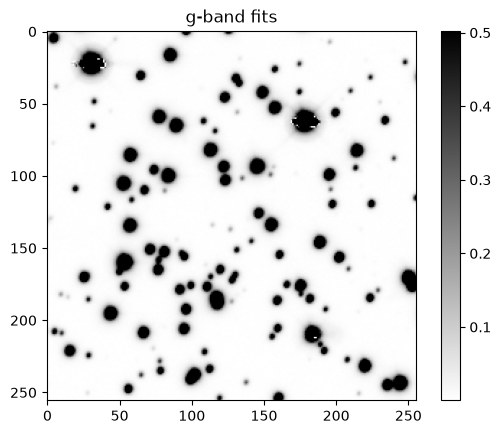

In [49]:
imdisplay(data_g)
plt.title("g-band fits")

Text(0.5, 1.0, 'r-band fits')

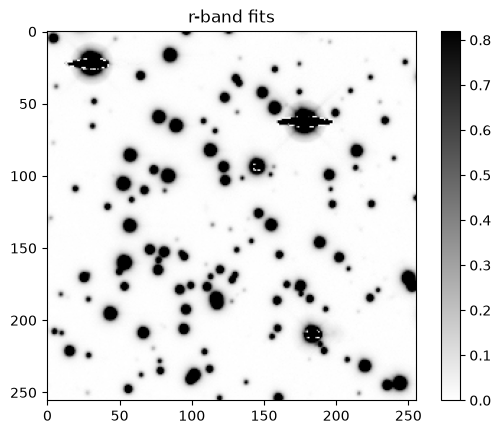

In [50]:
imdisplay(data_r)
plt.title("r-band fits")

Text(0.5, 1.0, 'z-band fits')

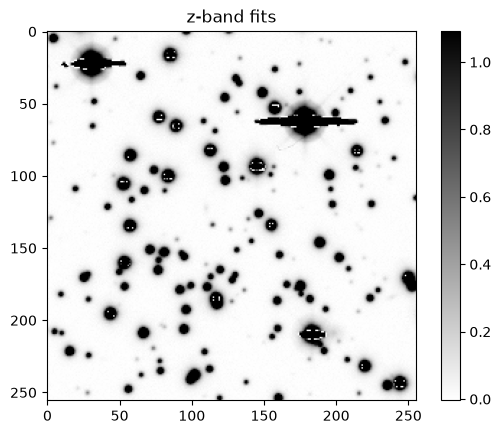

In [51]:
imdisplay(data_z)
plt.title("z-band fits")

In [52]:
"""
Display some pixel values
Cut out the rough position of a visible source in z band and changed bounds until it fit nicely
"""
Cutout_z=data_z[214:229, 10:23]
print(np.round(Cutout_z, 1,))

[[ 0.   0.   0.   0.   0.1  0.1  0.1  0.   0.   0.   0.   0.  -0. ]
 [ 0.   0.   0.1  0.1  0.1  0.1  0.1  0.1  0.   0.   0.   0.   0. ]
 [ 0.   0.   0.1  0.1  0.1  0.2  0.1  0.1  0.1  0.1  0.   0.   0. ]
 [ 0.   0.1  0.1  0.2  0.3  0.3  0.3  0.2  0.2  0.1  0.1  0.1  0. ]
 [ 0.1  0.1  0.2  0.4  0.6  0.9  0.8  0.6  0.4  0.2  0.1  0.   0. ]
 [ 0.1  0.2  0.3  0.7  1.5  2.5  2.5  1.5  0.7  0.3  0.2  0.1  0.1]
 [ 0.1  0.2  0.5  1.3  3.7  7.1  7.1  3.8  1.4  0.5  0.2  0.1  0.1]
 [ 0.1  0.2  0.7  2.1  6.5 13.1 13.2  6.4  2.1  0.7  0.3  0.1  0.1]
 [ 0.1  0.2  0.7  2.   6.3 12.2 12.1  5.8  1.9  0.6  0.2  0.1  0.1]
 [ 0.1  0.2  0.5  1.3  3.1  5.4  5.   2.7  1.1  0.4  0.2  0.1  0.1]
 [ 0.1  0.2  0.3  0.6  1.1  1.6  1.4  0.9  0.5  0.2  0.1  0.1  0. ]
 [ 0.1  0.1  0.2  0.3  0.4  0.5  0.5  0.3  0.2  0.1  0.1  0.1  0. ]
 [ 0.   0.1  0.1  0.1  0.2  0.2  0.2  0.1  0.1  0.1  0.1  0.   0. ]
 [ 0.   0.   0.   0.1  0.1  0.1  0.1  0.1  0.1  0.   0.   0.   0. ]
 [ 0.   0.   0.   0.   0.   0.1  0.   0.1  0.   

In [53]:
#Pixel values: 
for key in header:
        if key.startswith('CD'):
                print(key, '=', header[key])

#CD1_1 and CD2_2 store the coordinate change per pixel in degrees. Convert to arcseconds

CD1_arcsec=header["CD1_1"]*3600
print(CD1_arcsec)

#Since the values are equal just opposite sign RA/Dec have same scale.
print("Pixel scale is .5 arcsec by .5 arcsec")

CD1_1 = -0.000138888888888889
CD1_2 = 0.0
CD2_1 = 0.0
CD2_2 = 0.000138888888888889
-0.5000000000000004
Pixel scale is .5 arcsec by .5 arcsec


In [ ]:
#The data is measured in nanomaggies. An example of converting one point to magnitude:

peak = np.max(Cutout_z) #Take highest pixel in the cutout of a star from 2 cells ago

def nanomaggie_to_ABmag(nano): #make a function to convert to magnitude
    ABmag=22.5 - 2.5*np.log10(nano)
    return ABmag

print("peak pixel in cutout (nanomaggies) =", peak) #value from legacy survey
print("magnitude of that pixel =", nanomaggie_to_ABmag(peak)) #value converted to AB magnitude

peak pixel in cutout (nanomaggies) = 13.179736137390137
magnitude of that pixel = 19.70023321092986
